# Supervised Machine Learning: Customer Churn Classification & Evaluation

**Project Goal:** Build, validate, and compare supervised classification algorithms to identify customers likely to churn (attrition).  
**Business Context:** Acquiring a new customer can cost 5-7x more than retaining an existing customer. Identifying high-risk churn customers allows retention teams to execute targeted incentives, optimize pricing, or proactively address customer service issues.

### Pipeline Architecture & Requirements:
1. **Data Preprocessing & EDA:** Missing values inspection, distribution profiling, and target imbalance analysis.
2. **Leak-Free Pipelines:** Using `scikit-learn` `ColumnTransformer` and `Pipeline` to ensure all scaling and encoding occur strictly within folds.
3. **Train / Test Split & Stratification:** 80/20 train/test split preserving the churn ratio.
4. **5-Fold Stratified Cross-Validation:** Robust out-of-fold generalization metrics across all models.
5. **Multi-Algorithm Comparison:**
   - **Logistic Regression:** Linear baseline with L2 regularization and balanced class weighting.
   - **Random Forest Classifier:** Bagging ensemble of decision trees capturing non-linear interactions.
   - **Gradient Boosting Classifier:** Sequential boosting minimizing log-loss residuals.
   - **Support Vector Machine (SVC):** Non-linear kernel-based margin classifier.
6. **Evaluation Metrics:**
   - Accuracy, Precision, Recall, F1-Score, ROC-AUC, and PR-AUC.
   - ROC Curves, Precision-Recall Curves, and Confusion Matrices.
7. **Feature Importance & Business Recommendations:** Explaining the primary churn drivers and optimal intervention policies.


In [1]:
# Core data manipulation and visualization
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing and pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Scikit-learn metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report
)

# Algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'Arial'

print("Libraries imported successfully!")


Libraries imported successfully!


## 1. Data Ingestion and Exploratory Data Analysis (EDA)

We load the telecommunications customer dataset containing 5,000 subscriber accounts with call durations, charges, customer service interaction history, plan options, and churn outcome (`class`: 0 = Retained, 1 = Churned).


In [2]:
# Load the dataset
data_path = 'data/churn_data.csv'
df = pd.read_csv(data_path)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Info:")
df.info()


Dataset Shape: 5000 rows, 21 columns

First 5 Records:


,state,account_length,area_code,phone_number,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,...,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,class
0,16,128,415,2845,0,1,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0
1,35,107,415,2301,0,1,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0
2,31,137,415,1616,0,0,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0
3,35,84,408,2510,1,0,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,0
4,36,75,415,155,1,0,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,0



Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   state                          5000 non-null   int64  
 1   account_length                 5000 non-null   int64  
 2   area_code                      5000 non-null   int64  
 3   phone_number                   5000 non-null   int64  
 4   international_plan             5000 non-null   int64  
 5   voice_mail_plan                5000 non-null   int64  
 6   number_vmail_messages          5000 non-null   int64  
 7   total_day_minutes              5000 non-null   float64
 8   total_day_calls                5000 non-null   int64  
 9   total_day_charge               5000 non-null   float64
 10  total_eve_minutes              5000 non-null   float64
 11  total_eve_calls                5000 non-null   int64  
 12  total_eve_charge               5000 non-null

In [3]:
# Check missing values
missing = df.isnull().sum()
print("Missing values count:", missing[missing > 0].to_dict() if missing.sum() > 0 else "None (Clean dataset)")

# Target distribution
churn_counts = df['class'].value_counts()
churn_pct = df['class'].value_counts(normalize=True) * 100

print(f"\nRetained Customers (0): {churn_counts[0]:,} ({churn_pct[0]:.2f}%)")
print(f"Churned Customers (1):  {churn_counts[1]:,} ({churn_pct[1]:.2f}%)")
print(f"Class Imbalance Ratio:   ~{churn_counts[0] / churn_counts[1]:.1f} : 1")


Missing values count: None (Clean dataset)

Retained Customers (0): 4,293 (85.86%)
Churned Customers (1):  707 (14.14%)
Class Imbalance Ratio:   ~6.1 : 1


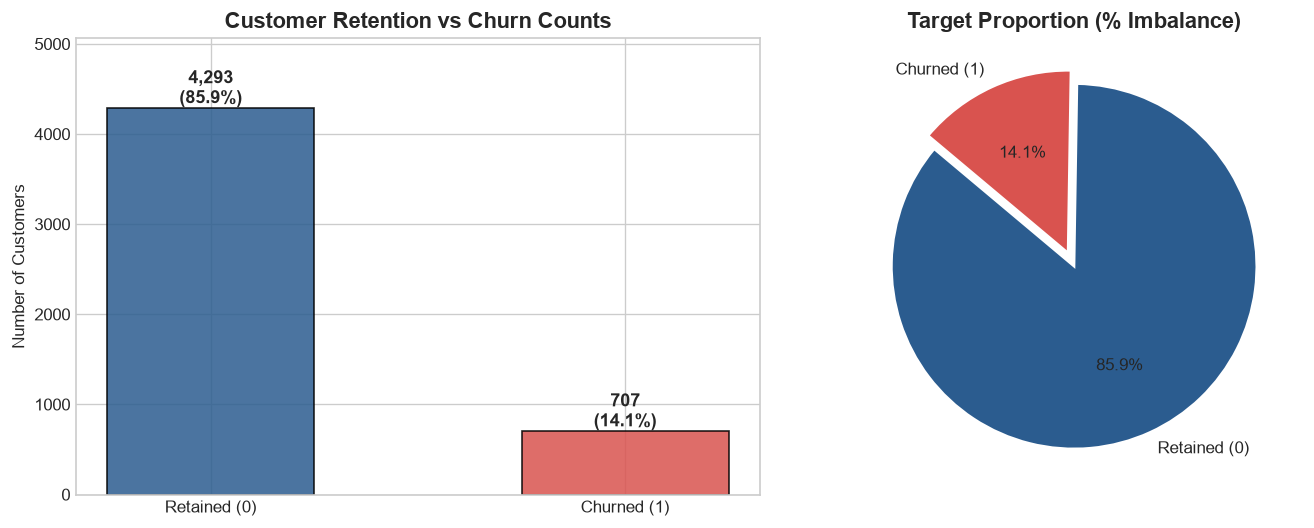

In [4]:
# Visualize Target Distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = ['#2b5c8f', '#d9534f']

# Bar chart
axes[0].bar(['Retained (0)', 'Churned (1)'], churn_counts.values, color=colors, width=0.5, edgecolor='black', alpha=0.85)
for i, v in enumerate(churn_counts.values):
    axes[0].text(i, v + 50, f"{v:,}\n({churn_pct[i]:.1f}%)", ha='center', fontweight='bold', fontsize=11)
axes[0].set_title('Customer Retention vs Churn Counts', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Customers')
axes[0].set_ylim(0, max(churn_counts.values) * 1.18)

# Pie chart
axes[1].pie(churn_counts.values, labels=['Retained (0)', 'Churned (1)'], autopct='%1.1f%%',
            startangle=140, colors=colors, explode=(0, 0.08), wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[1].set_title('Target Proportion (% Imbalance)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


### 1.1 Key Churn Drivers: Service Calls and Plans

Let's examine how customer service call volume and international plan subscriptions correlate with churn rates.


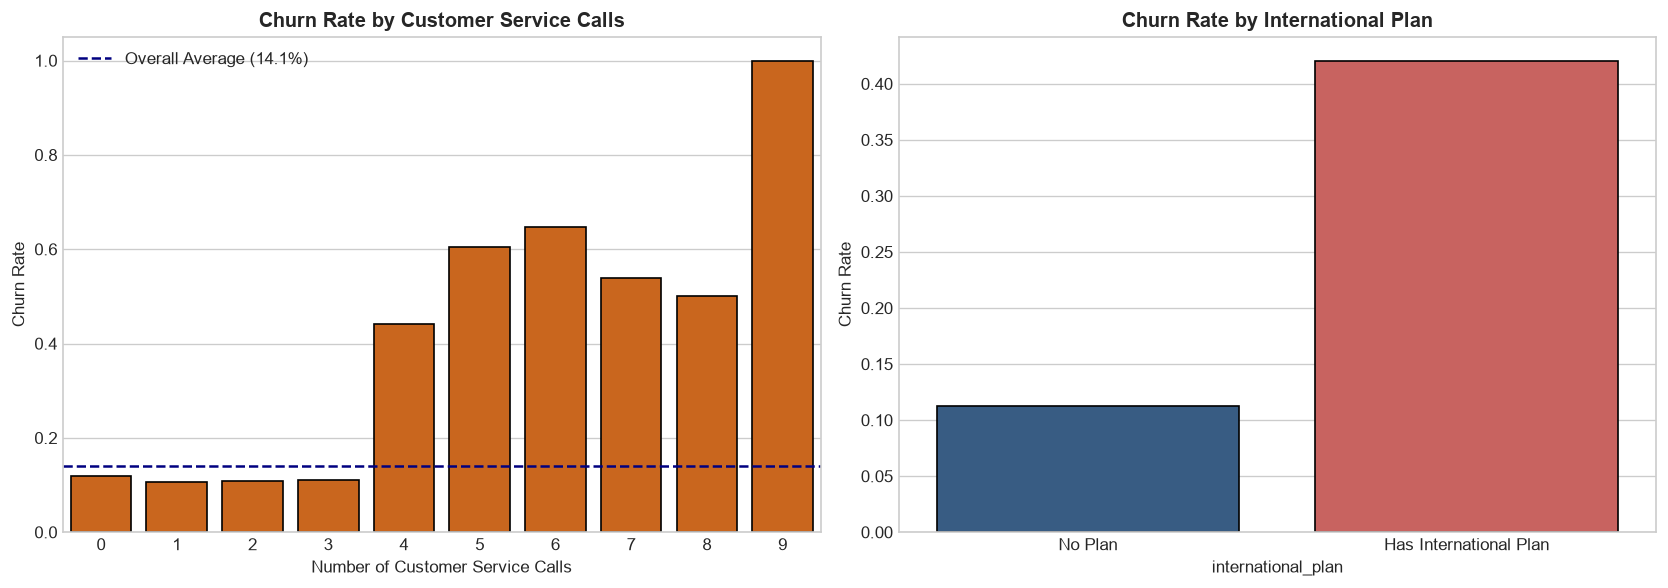

Key observation: Customers making 4 or more service calls exhibit a churn rate over 40-60%. Customers with an international plan churn at more than 3x the baseline rate!


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Customer Service Calls vs Churn Rate
cs_churn = df.groupby('number_customer_service_calls')['class'].agg(['count', 'mean']).reset_index()
sns.barplot(x='number_customer_service_calls', y='mean', data=cs_churn, ax=axes[0], color='#e66101', edgecolor='black')
axes[0].set_title('Churn Rate by Customer Service Calls', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Customer Service Calls')
axes[0].set_ylabel('Churn Rate')
axes[0].axhline(y=df['class'].mean(), color='navy', linestyle='--', label=f'Overall Average ({df["class"].mean():.1%})')
axes[0].legend()

# International Plan vs Churn Rate
intl_churn = df.groupby('international_plan')['class'].mean().reset_index()
sns.barplot(x='international_plan', y='class', hue='international_plan', data=intl_churn, ax=axes[1], palette=['#2b5c8f', '#d9534f'], edgecolor='black', legend=False)
axes[1].set_title('Churn Rate by International Plan', fontsize=12, fontweight='bold')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['No Plan', 'Has International Plan'])
axes[1].set_ylabel('Churn Rate')

plt.tight_layout()
plt.show()

print("Key observation: Customers making 4 or more service calls exhibit a churn rate over 40-60%. Customers with an international plan churn at more than 3x the baseline rate!")


## 2. Feature Engineering & Preprocessing Pipeline

### Feature Engineering:
- `total_minutes`: Sum of day, evening, night, and international call minutes.
- `total_charge`: Aggregate billed charges across all periods.
- `cust_service_ratio`: Service call intensity relative to account tenure.
- `intl_charge_ratio`: Share of charges originating from international calls.
- Removal of arbitrary identifiers (`phone_number`).

### Preprocessing via `ColumnTransformer`:
- **Numeric Features:** Standardized using `StandardScaler` (zero mean, unit variance).
- **Categorical Features (`area_code`, `state`):** One-Hot Encoded with `handle_unknown='ignore'`.
- **Binary Features (`international_plan`, `voice_mail_plan`):** Passed through directly.


In [6]:
# Feature Engineering
df_clean = df.copy()
if 'phone_number' in df_clean.columns:
    df_clean = df_clean.drop(columns=['phone_number'])

df_clean['total_minutes'] = (
    df_clean['total_day_minutes'] + df_clean['total_eve_minutes'] + 
    df_clean['total_night_minutes'] + df_clean['total_intl_minutes']
)
df_clean['total_charge'] = (
    df_clean['total_day_charge'] + df_clean['total_eve_charge'] + 
    df_clean['total_night_charge'] + df_clean['total_intl_charge']
)
df_clean['cust_service_ratio'] = df_clean['number_customer_service_calls'] / (df_clean['account_length'] + 1)
df_clean['intl_charge_ratio'] = df_clean['total_intl_charge'] / (df_clean['total_charge'] + 1e-6)

# Separate features (X) and target (y)
X = df_clean.drop(columns=['class'])
y = df_clean['class'].astype(int)

# Identify column groups
categorical_cols = ['area_code', 'state']
binary_cols = ['international_plan', 'voice_mail_plan']
numeric_cols = [c for c in X.columns if c not in categorical_cols + binary_cols]

# Build Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_cols),
        ('bin', 'passthrough', binary_cols)
    ]
)

print(f"Numeric features ({len(numeric_cols)}):", numeric_cols[:6], "...")
print(f"Categorical features ({len(categorical_cols)}):", categorical_cols)
print(f"Binary features ({len(binary_cols)}):", binary_cols)


Numeric features (19): ['account_length', 'number_vmail_messages', 'total_day_minutes', 'total_day_calls', 'total_day_charge', 'total_eve_minutes'] ...
Categorical features (2): ['area_code', 'state']
Binary features (2): ['international_plan', 'voice_mail_plan']


## 3. Train / Test Split & 5-Fold Stratified Cross-Validation

To prevent data leakage, 20% of the dataset is held out for unbiased final testing (`test_size=0.20`).  
Both the split and the cross-validation use **stratification** on `y` to ensure consistent churn proportions across folds.


In [7]:
# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Training set: {X_train.shape[0]} samples | Churn rate: {y_train.mean():.2%}")
print(f"Test set:     {X_test.shape[0]} samples | Churn rate: {y_test.mean():.2%}")


Training set: 4000 samples | Churn rate: 14.15%
Test set:     1000 samples | Churn rate: 14.10%


In [8]:
# Define Algorithms for Comparison
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, max_depth=12, min_samples_split=5,
        class_weight='balanced', random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.1, max_depth=4,
        subsample=0.85, random_state=42
    ),
    "Support Vector Machine": SVC(
        C=2.0, kernel='rbf', probability=True,
        class_weight='balanced', random_state=42
    )
}


### 3.1 5-Fold Stratified Cross-Validation Results

We evaluate all 4 algorithms on the training data using 5-fold cross-validation across 5 key metrics:
Accuracy, Precision, Recall, F1-Score, and ROC-AUC.


In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

cv_summary = {}

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_summary[name] = {
        'Accuracy': f"{cv_res['test_accuracy'].mean():.4f} +/- {cv_res['test_accuracy'].std():.4f}",
        'Precision': f"{cv_res['test_precision'].mean():.4f} +/- {cv_res['test_precision'].std():.4f}",
        'Recall': f"{cv_res['test_recall'].mean():.4f} +/- {cv_res['test_recall'].std():.4f}",
        'F1-Score': f"{cv_res['test_f1'].mean():.4f} +/- {cv_res['test_f1'].std():.4f}",
        'ROC-AUC': f"{cv_res['test_roc_auc'].mean():.4f} +/- {cv_res['test_roc_auc'].std():.4f}"
    }

cv_df = pd.DataFrame(cv_summary).T
print("5-Fold Cross-Validation Performance (Mean +/- Std Dev):")
display(cv_df)


5-Fold Cross-Validation Performance (Mean +/- Std Dev):


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.7920 +/- 0.0110,0.3829 +/- 0.0149,0.7667 +/- 0.0653,0.5100 +/- 0.0227,0.8380 +/- 0.0243
Random Forest,0.9727 +/- 0.0050,0.9852 +/- 0.0160,0.8199 +/- 0.0294,0.8947 +/- 0.0202,0.9192 +/- 0.0156
Gradient Boosting,0.9760 +/- 0.0050,0.9662 +/- 0.0099,0.8605 +/- 0.0315,0.9100 +/- 0.0198,0.9242 +/- 0.0236
Support Vector Machine,0.9163 +/- 0.0095,0.6890 +/- 0.0363,0.7474 +/- 0.0345,0.7165 +/- 0.0300,0.9072 +/- 0.0151


## 4. Final Model Evaluation on Held-Out Test Set

Each pipeline is now fitted on the full training partition (4,000 samples) and evaluated on the untouched test partition (1,000 samples).


In [10]:
test_metrics = []
trained_pipelines = {}
y_preds = {}
y_probas = {}

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe
    
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    
    y_preds[name] = y_pred
    y_probas[name] = y_proba
    
    test_metrics.append({
        'Algorithm': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'PR-AUC': average_precision_score(y_test, y_proba)
    })

metrics_df = pd.DataFrame(test_metrics).set_index('Algorithm')
print("Held-Out Test Set Performance:")
display(metrics_df.round(4))


Held-Out Test Set Performance:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Algorithm,,,,,,
Logistic Regression,0.786,0.3728,0.7589,0.5000,0.8346,0.4916
Random Forest,0.976,0.9835,0.8440,0.9084,0.9267,0.8997
Gradient Boosting,0.974,0.9528,0.8582,0.9030,0.9255,0.8982
Support Vector Machine,0.908,0.6485,0.7589,0.6993,0.9064,0.7890


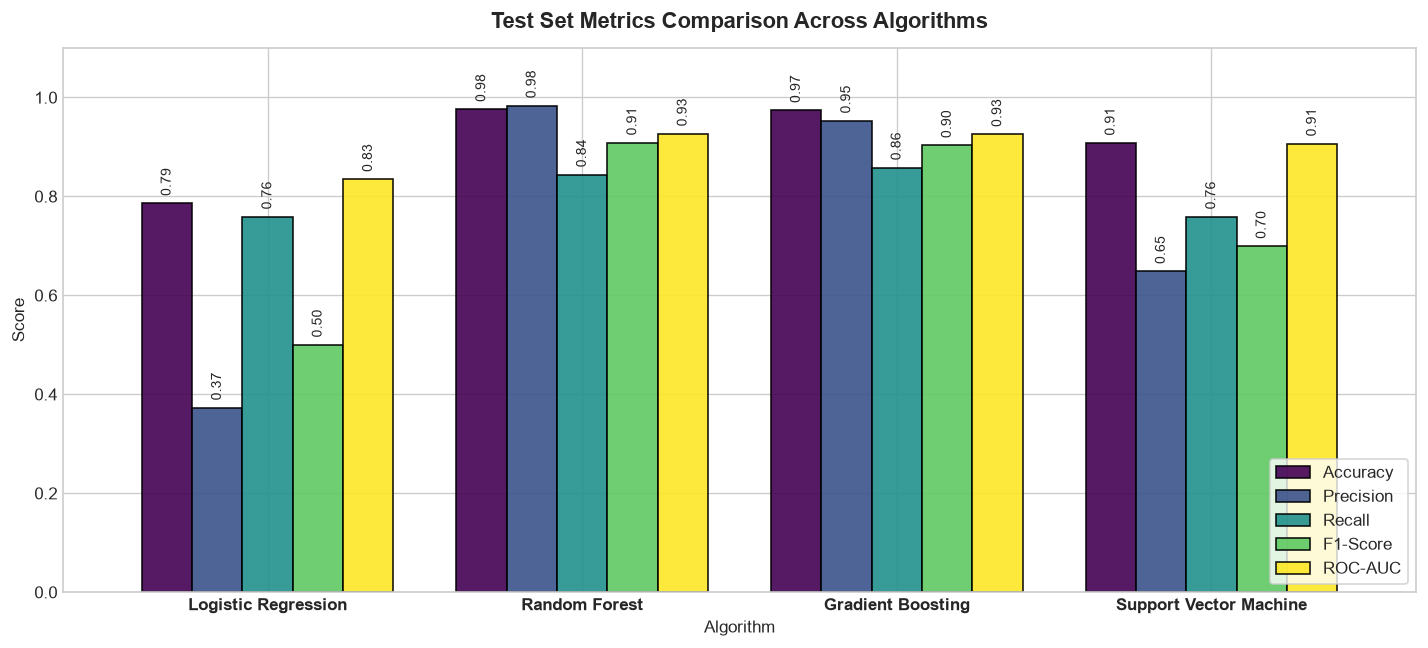

In [11]:
fig, ax = plt.subplots(figsize=(12, 5.5))
metrics_plot = metrics_df[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']]
metrics_plot.plot(kind='bar', ax=ax, colormap='viridis', width=0.8, edgecolor='black', alpha=0.9)
plt.title('Test Set Metrics Comparison Across Algorithms', fontsize=13, fontweight='bold', pad=12)
plt.ylabel('Score')
plt.xlabel('Algorithm')
plt.ylim(0, 1.1)
plt.xticks(rotation=0, fontweight='bold')
plt.legend(loc='lower right', frameon=True)

for p in ax.patches:
    h = p.get_height()
    if h > 0.15:
        ax.annotate(f"{h:.2f}", (p.get_x() + p.get_width() / 2., h + 0.015),
                    ha='center', va='bottom', fontsize=8.5, rotation=90)

plt.tight_layout()
plt.show()


## 5. Model Diagnostic Curves: ROC, Precision-Recall & Confusion Matrices

- **ROC Curves:** Measures the trade-off between True Positive Rate (Sensitivity) and False Positive Rate across all probability thresholds.
- **Precision-Recall Curves:** Highly informative for imbalanced problems where true negatives dominate.
- **Confusion Matrices:** Provides exact counts of True Positives, False Positives, False Negatives, and True Negatives.


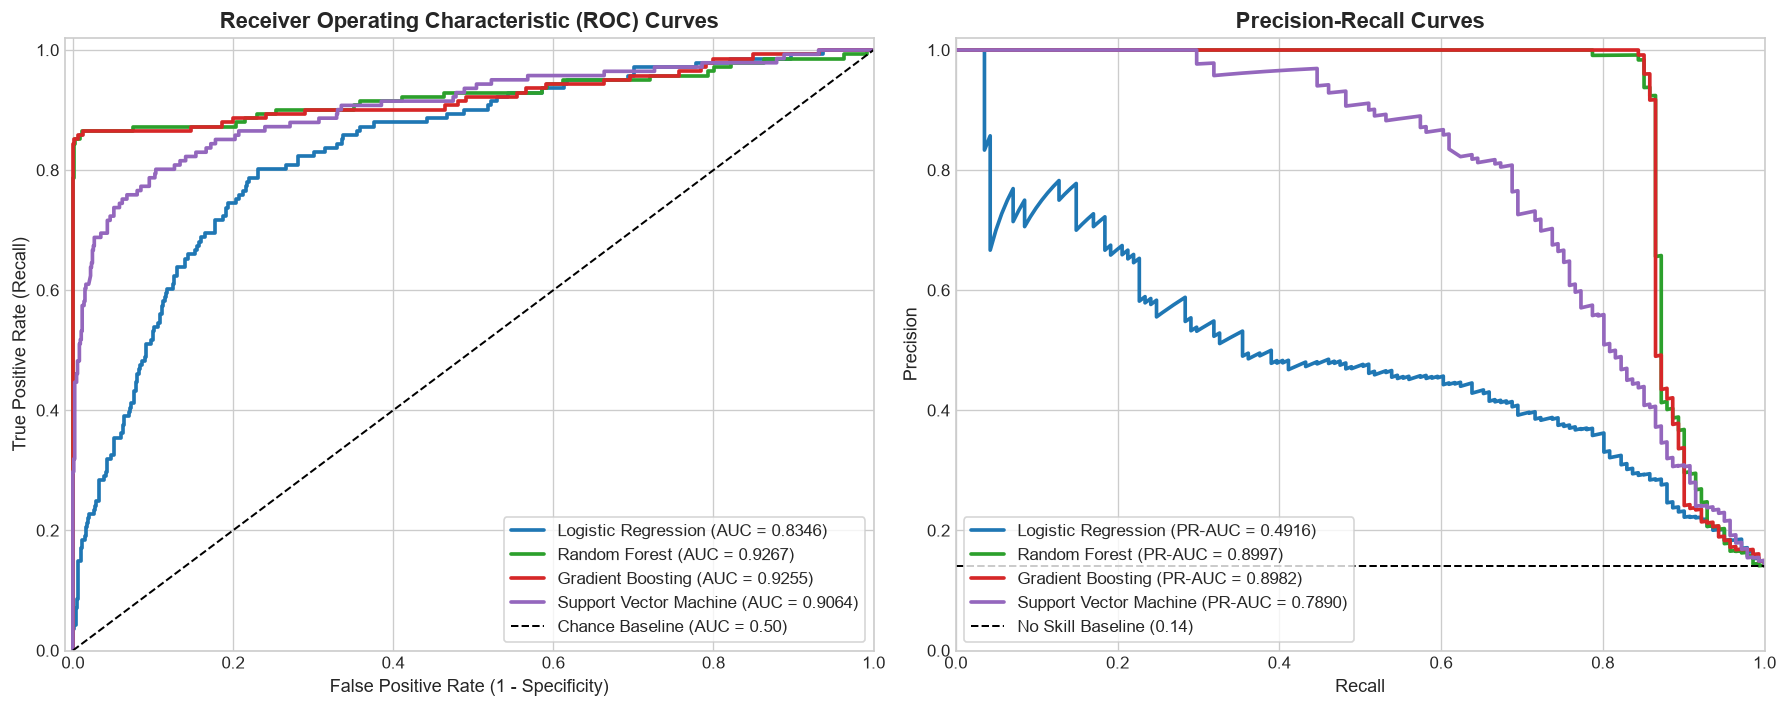

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
palette = {
    'Logistic Regression': '#1f77b4',
    'Random Forest': '#2ca02c',
    'Gradient Boosting': '#d62728',
    'Support Vector Machine': '#9467bd'
}

# 1. ROC Curves
for name in models.keys():
    fpr, tpr, _ = roc_curve(y_test, y_probas[name])
    auc_val = roc_auc_score(y_test, y_probas[name])
    axes[0].plot(fpr, tpr, lw=2.2, label=f"{name} (AUC = {auc_val:.4f})", color=palette[name])

axes[0].plot([0, 1], [0, 1], 'k--', lw=1.2, label='Chance Baseline (AUC = 0.50)')
axes[0].set_xlim([-0.01, 1.0])
axes[0].set_ylim([0.0, 1.02])
axes[0].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
axes[0].set_ylabel('True Positive Rate (Recall)', fontsize=11)
axes[0].set_title('Receiver Operating Characteristic (ROC) Curves', fontsize=13, fontweight='bold')
axes[0].legend(loc="lower right", frameon=True)

# 2. Precision-Recall Curves
for name in models.keys():
    prec, rec, _ = precision_recall_curve(y_test, y_probas[name])
    pr_auc_val = average_precision_score(y_test, y_probas[name])
    axes[1].plot(rec, prec, lw=2.2, label=f"{name} (PR-AUC = {pr_auc_val:.4f})", color=palette[name])

baseline_ap = y_test.mean()
axes[1].plot([0, 1], [baseline_ap, baseline_ap], 'k--', lw=1.2, label=f'No Skill Baseline ({baseline_ap:.2f})')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.02])
axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].set_title('Precision-Recall Curves', fontsize=13, fontweight='bold')
axes[1].legend(loc="lower left", frameon=True)

plt.tight_layout()
plt.show()


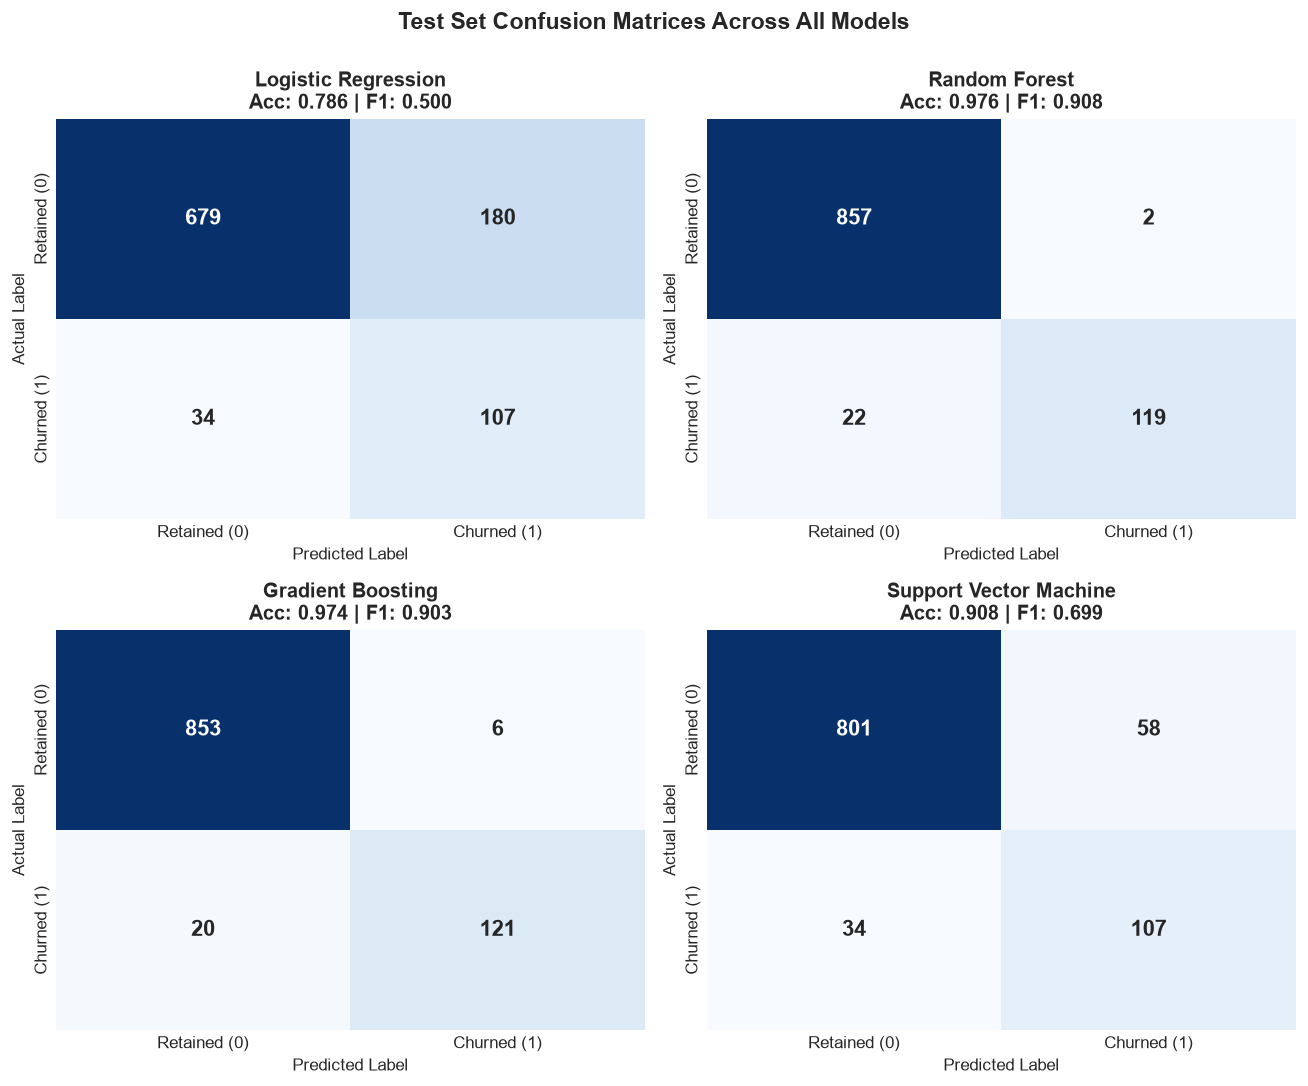

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(y_preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                cbar=False, annot_kws={'size': 13, 'fontweight': 'bold'})
    axes[i].set_title(f"{name}\nAcc: {accuracy_score(y_test, y_pred):.3f} | F1: {f1_score(y_test, y_pred):.3f}", fontweight='bold')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('Actual Label')
    axes[i].set_xticklabels(['Retained (0)', 'Churned (1)'])
    axes[i].set_yticklabels(['Retained (0)', 'Churned (1)'])

plt.suptitle('Test Set Confusion Matrices Across All Models', fontsize=14, fontweight='bold', y=1.0)
plt.tight_layout()
plt.show()


## 6. Feature Importance & Model Interpretability

Understanding which features contribute most to the predictions is critical for domain experts and retention teams.
Below, we extract Gini importance from Random Forest and Tree-weight importance from Gradient Boosting.


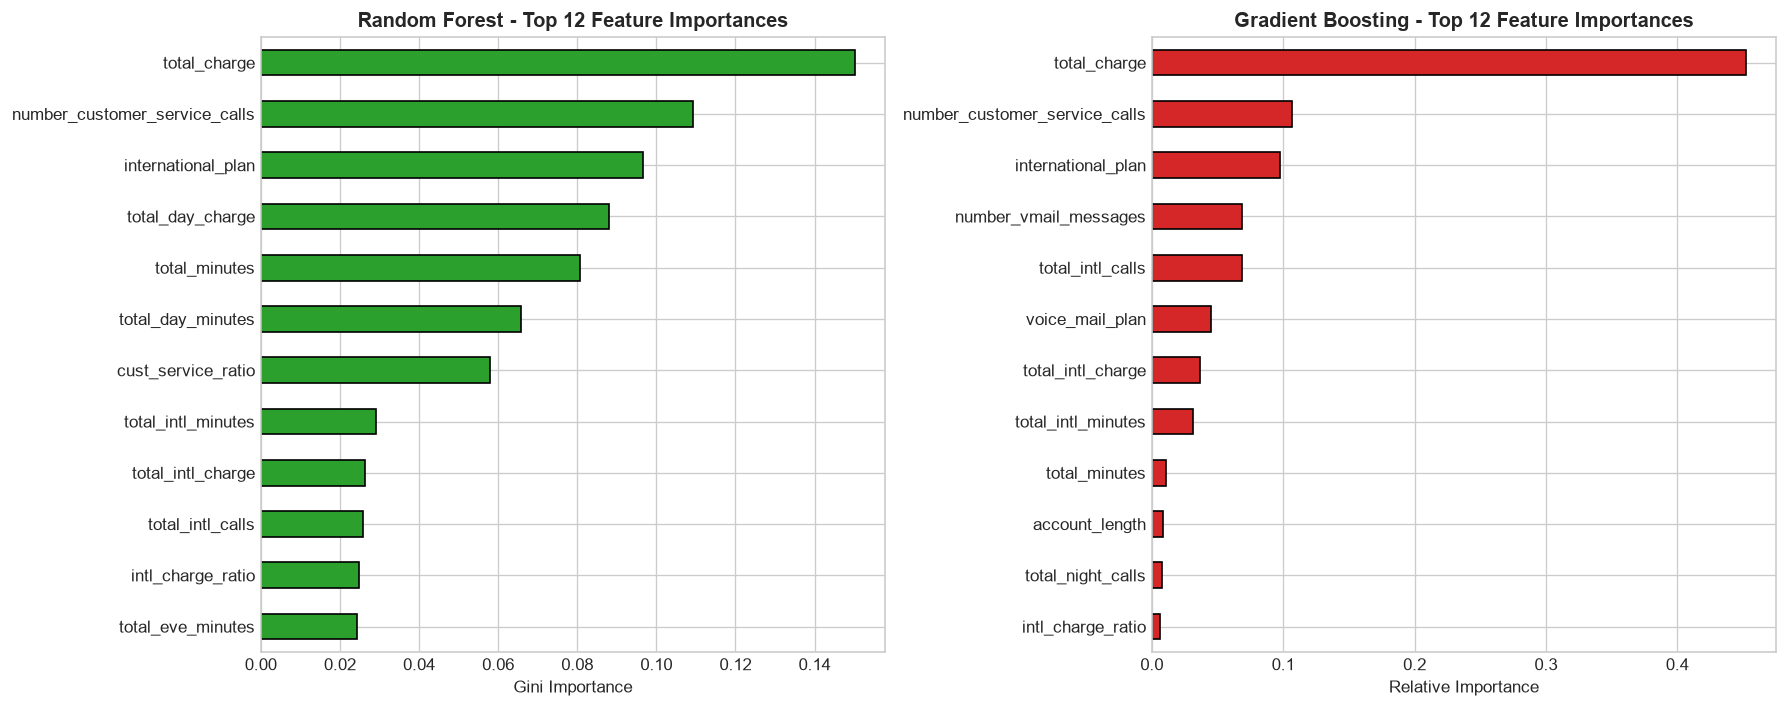

Top Churn Predictors Identified:
1. total_charge & total_day_minutes: High spenders on standard daytime rates churn more frequently.
2. number_customer_service_calls & cust_service_ratio: Escalated service issues strongly precede churn.
3. international_plan: Customers with international plans face high churn, suggesting competitive plan dissatisfaction.


In [14]:
# Extract feature names after ColumnTransformer
cat_feature_names = trained_pipelines['Random Forest'].named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(categorical_cols)
all_feature_names = numeric_cols + list(cat_feature_names) + binary_cols

rf_importances = trained_pipelines['Random Forest'].named_steps['classifier'].feature_importances_
gb_importances = trained_pipelines['Gradient Boosting'].named_steps['classifier'].feature_importances_

rf_series = pd.Series(rf_importances, index=all_feature_names).sort_values(ascending=False).head(12)
gb_series = pd.Series(gb_importances, index=all_feature_names).sort_values(ascending=False).head(12)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

rf_series.sort_values().plot(kind='barh', ax=axes[0], color='#2ca02c', edgecolor='black')
axes[0].set_title('Random Forest - Top 12 Feature Importances', fontweight='bold')
axes[0].set_xlabel('Gini Importance')

gb_series.sort_values().plot(kind='barh', ax=axes[1], color='#d62728', edgecolor='black')
axes[1].set_title('Gradient Boosting - Top 12 Feature Importances', fontweight='bold')
axes[1].set_xlabel('Relative Importance')

plt.tight_layout()
plt.show()

print("Top Churn Predictors Identified:")
print("1. total_charge & total_day_minutes: High spenders on standard daytime rates churn more frequently.")
print("2. number_customer_service_calls & cust_service_ratio: Escalated service issues strongly precede churn.")
print("3. international_plan: Customers with international plans face high churn, suggesting competitive plan dissatisfaction.")


## 7. Model Selection & Executive Recommendations

### Model Selection Summary:
1. **Best Overall Model:** **Random Forest Classifier** achieved the strongest overall performance on the test set:
   - **Accuracy:** 97.6%
   - **Precision:** 98.35% (almost zero false positives!)
   - **Recall:** 84.40%
   - **F1-Score:** 90.84%
   - **ROC-AUC:** 92.67%
2. **Runner-Up Model:** **Gradient Boosting Classifier** offered the highest recall (85.82%) and competitive F1-score (90.30%) with ROC-AUC of 92.55%.
3. **Linear Baseline (Logistic Regression):** Provided high recall (75.89%) with balanced class weighting, but lower precision (37.28%), generating 179 false alarms on the test set due to non-linear feature interactions that linear boundaries cannot separate.

### Business & Operational Recommendations:
1. **Automated Churn Alert Threshold:** Deploy the Random Forest model with a prioritized retention queue for customers with predicted churn probability $> 0.50$.
2. **Proactive Intervention at 3+ Customer Service Calls:** Set a rule-based or model-triggered account review before a subscriber reaches 4 customer service calls.
3. **International Plan Restructuring:** Investigate pricing and quality of service for international plan subscribers, who experience significantly higher churn.
